# Unsupervised Asteroid Clustering with K-Means

Group asteroids using orbital elements without training on PHA, NEO, or orbit-class labels. After clustering, compare groups with those existing labels to look for astronomical structure, while remembering that K-Means finds geometric groups rather than verified asteroid families.

## 1. Import libraries and set paths

In [30]:
from pathlib import Path
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / "Data" / "pha_dataset_cleaned.csv"
RANDOM_STATE = 42
MAX_MODEL_ROWS = 100_000
MAX_SILHOUETTE_ROWS = 15_000
print("Input dataset:", DATA_PATH)

Input dataset: d:\Guvi\PDA\Data\pha_dataset_cleaned.csv


## 2. Load orbital elements and labels for later comparison

`pha`, `neo`, and `class` are loaded only for post-clustering interpretation. They are explicitly excluded from the clustering features.

In [21]:
columns_to_load = ["id", "a", "e", "i", "om", "w", "pha", "neo", "class"]
df = pd.read_csv(DATA_PATH, usecols=columns_to_load, low_memory=False)
print(f"Rows loaded: {len(df):,}")
print("Orbital-element columns:", ["a", "e", "i", "om", "w"])
display(df.head())
display(df[["a", "e", "i", "om", "w"]].describe().T)

Rows loaded: 958,524
Orbital-element columns: ['a', 'e', 'i', 'om', 'w']


,id,neo,pha,e,a,i,om,w,class
0,a0000001,N,N,0.076009,2.769165,10.594067,80.305531,73.597695,MBA
1,a0000002,N,N,0.229972,2.773841,34.832932,173.024741,310.202392,MBA
2,a0000003,N,N,0.256936,2.668285,12.991043,169.851482,248.066193,MBA
3,a0000004,N,N,0.088721,2.361418,7.141771,103.810804,150.728541,MBA
4,a0000005,N,N,0.190913,2.574037,5.367427,141.571026,358.648418,MBA


,count,mean,std,min,25%,50%,75%,max
a,958524.0,2.902143,39.719503,-14702.447872,2.387835,2.646969,3.001932,33488.895955
e,958524.0,0.156116,0.092643,0.000000,0.092193,0.145002,0.200650,1.855356
i,958524.0,9.054901,6.637656,0.007744,4.165419,7.415665,12.407550,175.082901
om,958524.0,168.456416,102.881707,0.000025,80.604399,159.826919,252.247751,359.999793
w,958524.0,181.369457,103.887995,0.000130,91.482063,182.358081,271.521589,359.999646


## 3. Prepare orbital features

Use semi-major axis (`a`), eccentricity (`e`), inclination (`i`), longitude of ascending node (`om`), and argument of perihelion (`w`). Semi-major axis is log-transformed to reduce the influence of its long tail. Angular features are converted to sine/cosine so values near 0° and 360° are close in feature space. Mean anomaly is omitted because it changes with orbital phase.

In [22]:
orbital_numeric = ["a", "e", "i", "om", "w"]
for column in orbital_numeric:
    df[column] = pd.to_numeric(df[column], errors="coerce")

before_filter = len(df)
valid_orbits = df.dropna(subset=orbital_numeric).copy()
valid_orbits = valid_orbits[
    (valid_orbits["a"] > 0)
    & valid_orbits["e"].between(0, 1, inclusive="left")
    & valid_orbits["i"].between(0, 180)
].copy()
print(f"Valid orbital records: {len(valid_orbits):,}")
print(f"Rows excluded for missing/invalid orbital elements: {before_filter - len(valid_orbits):,}")

angle_radians = np.deg2rad(valid_orbits[["om", "w"]])
X_orbit = pd.DataFrame(index=valid_orbits.index)
X_orbit["log_a"] = np.log1p(valid_orbits["a"])
X_orbit["e"] = valid_orbits["e"]
X_orbit["i"] = valid_orbits["i"]
for angle in ["om", "w"]:
    X_orbit[f"{angle}_sin"] = np.sin(angle_radians[angle])
    X_orbit[f"{angle}_cos"] = np.cos(angle_radians[angle])

print("Features used by K-Means:", X_orbit.columns.tolist())
print("Labels are not present in X_orbit:", not any(label in X_orbit.columns for label in ["pha", "neo", "class"]))

Valid orbital records: 958,520
Rows excluded for missing/invalid orbital elements: 4
Features used by K-Means: ['log_a', 'e', 'i', 'om_sin', 'om_cos', 'w_sin', 'w_cos']
Labels are not present in X_orbit: True


## 4. Standardize features and create reproducible samples

In [23]:
# Standardize on the full valid feature set; K-Means is distance-based and needs comparable scales.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_orbit)

rng = np.random.default_rng(RANDOM_STATE)
model_sample_size = min(MAX_MODEL_ROWS, len(X_scaled))
model_indices = np.sort(rng.choice(len(X_scaled), size=model_sample_size, replace=False))
X_model_sample = X_scaled[model_indices]
print(f"Rows used to fit candidate/final K-Means: {model_sample_size:,}")
print(f"Rows available to assign to clusters: {len(X_scaled):,}")

Rows used to fit candidate/final K-Means: 100,000
Rows available to assign to clusters: 958,520


## 5. Compare candidate cluster counts

Evaluate K values from 2 to 10 using inertia and silhouette score on the same reproducible sample. The silhouette calculation uses a smaller sample to keep runtime practical. Use the plots as guidance: the silhouette score does not establish the true number of astronomical families.

,inertia,silhouette
k,,
2,608922.812070,0.151460
3,549081.414500,0.143256
4,505478.662154,0.137692
5,453571.869114,0.147967
6,447156.740548,0.146094
7,387406.602216,0.152100
8,364728.072985,0.154891
9,341353.660404,0.159132
10,322086.511990,0.167536


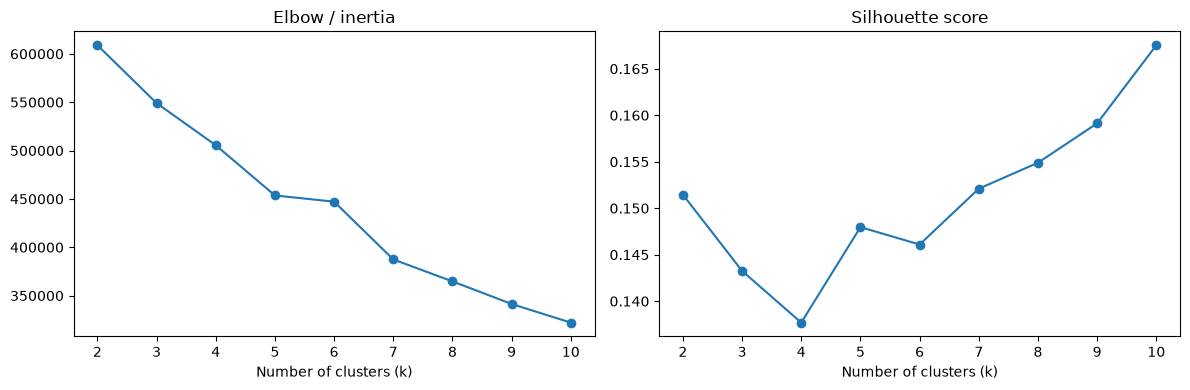

In [24]:
candidate_ks = range(2, 11)
silhouette_size = min(MAX_SILHOUETTE_ROWS, len(X_model_sample))
silhouette_indices = np.sort(rng.choice(len(X_model_sample), size=silhouette_size, replace=False))
X_silhouette = X_model_sample[silhouette_indices]

candidate_results = []
for k in candidate_ks:
    candidate_model = KMeans(n_clusters=k, n_init=5, random_state=RANDOM_STATE)
    candidate_model.fit(X_model_sample)
    silhouette_labels = candidate_model.predict(X_silhouette)
    candidate_results.append({
        "k": k,
        "inertia": candidate_model.inertia_,
        "silhouette": silhouette_score(X_silhouette, silhouette_labels),
    })

k_results = pd.DataFrame(candidate_results).set_index("k")
display(k_results)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k_results["inertia"].plot(marker="o", ax=axes[0], title="Elbow / inertia")
k_results["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette score")
axes[0].set_xlabel("Number of clusters (k)")
axes[1].set_xlabel("Number of clusters (k)")
plt.tight_layout()
plt.show()

## 6. Fit the final K-Means model

**Choice of k:** Among the tested values (k=2 through 10), k=10 has the highest sampled silhouette score (0.1675), so it is selected for the final fit. Inertia decreases as k increases, as expected, but its curve does not show one clear elbow; the silhouette comparison therefore provides the main selection evidence. The score is modest, suggesting overlapping orbital groups rather than sharply separated clusters. Since k=10 is the upper end of the tested range, this is the best candidate within that range, not proof of a global optimum; testing larger k values could be a useful follow-up.

Interpret the clusters cautiously: K-Means favors roughly spherical clusters and can split continuous orbital distributions into artificial groups.

In [25]:
BEST_K = int(k_results["silhouette"].idxmax())
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE)
kmeans.fit(X_model_sample)
cluster_labels = kmeans.predict(X_scaled)
clustered = valid_orbits.copy()
clustered["cluster"] = cluster_labels
print(f"Selected k={BEST_K} by the highest sampled silhouette score.")
print("Clustered rows:", f"{len(clustered):,}")
display(clustered["cluster"].value_counts().sort_index().rename("asteroid_count").to_frame())

Selected k=10 by the highest sampled silhouette score.
Clustered rows: 958,520


,asteroid_count
cluster,
0,148692
1,101148
2,93924
3,139824
4,93251
5,22979
6,136977
7,3749
8,66832


## 7. Save and verify the best clustering model

Save the fitted scaler, K-Means estimator, and engineered feature names together. For new asteroid records, build the same seven orbital features (`log_a`, `e`, `i`, `om_sin`, `om_cos`, `w_sin`, `w_cos`) in this order before calling the saved scaler and estimator.

In [31]:
MODEL_DIR = PROJECT_ROOT / "Models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "asteroid_orbit_kmeans.pkl"

cluster_model = {
    "scaler": scaler,
    "kmeans": kmeans,
    "feature_columns": X_orbit.columns.tolist(),
    "n_clusters": BEST_K,
    "random_state": RANDOM_STATE,
}
with MODEL_PATH.open("wb") as model_file:
    pickle.dump(cluster_model, model_file, protocol=pickle.HIGHEST_PROTOCOL)

with MODEL_PATH.open("rb") as model_file:
    loaded_cluster_model = pickle.load(model_file)
check_size = min(100, len(X_orbit))
reloaded_predictions = loaded_cluster_model["kmeans"].predict(
    loaded_cluster_model["scaler"].transform(
        X_orbit.iloc[:check_size][loaded_cluster_model["feature_columns"]]
    )
)
assert np.array_equal(reloaded_predictions, cluster_labels[:check_size])
print(f"Saved and verified model: {MODEL_PATH}")
print(f"Clusters: {loaded_cluster_model['n_clusters']}; feature count: {len(loaded_cluster_model['feature_columns'])}")

Saved and verified model: d:\Guvi\PDA\Models\asteroid_orbit_kmeans.pkl
Clusters: 10; feature count: 7


## 8. Describe cluster orbital profiles

a                                         e                      \
          count       mean     median         std   count      mean    median   
cluster                                                                         
0        148692   2.696744   2.651911    0.388392  148692  0.161927  0.163581   
1        101148   2.717159   2.663671    0.405380  101148  0.116664  0.115345   
2         93924   2.717625   2.663743    0.434495   93924  0.114994  0.112299   
3        139824   2.707935   2.663617    0.415438  139824  0.161882  0.160887   
4         93251   2.680289   2.641873    0.420218   93251  0.113981  0.110251   
5         22979   2.219547   2.253823    0.727561   22979  0.500927  0.478042   
6        136977   2.686098   2.646512    0.415839  136977  0.158597  0.156932   
7          3749  65.423135  43.784963  571.571258    3749  0.236395  0.161765   
8         66832   2.573759   2.593968    0.716358   66832  0.164466  0.150863   
9        151144   2.700366   2.654379    0.396512  151144  0.162634  0.163759   

                        i                                       om  \
              std   count       mean     median        std   count   
cluster                                                              
0        0.069543  148692   7.678657   6.701818   4.516249  148692   
1        0.058664  101148   8.063383   7.114522   4.625310  101148   
2        0.058280   93924   7.758865   6.887002   4.632026   93924   
3        0.071632  139824   7.616819   6.751937   4.576582  139824   
4        0.057918   93251   7.836390   7.059727   4.724176   93251   
5        0.116955   22979  12.155753   9.467089   9.223878   22979   
6        0.070870  136977   7.501410   6.581530   4.594683  136977   
7        0.225963    3749  15.583447  10.604605  20.148122    3749   
8        0.095851   66832  24.822030  23.867612   5.387393   66832   
9        0.069853  151144   7.760451   6.784641   4.543283  151144   

                                                  w                          \
               mean      median         std   count        mean      median   
cluster                                                                       
0        129.225168  129.894312   37.163230  148692  224.449709  225.246864   
1         87.055349   86.526494   41.510384  101148   95.708195   95.383718   
2        190.038409  188.718241   40.569675   93924  221.287536  291.646460   
3        217.572496  216.812469   34.119972  139824  139.410768  139.463709   
4        229.082355  294.556575  132.495921   93251  217.448373  218.599261   
5        173.358027  171.656512  103.649526   22979  179.979928  180.502596   
6        269.499269  307.516450  108.256378  136977   96.060587   61.668076   
7        153.289739  139.149411   97.069434    3749  180.485639  181.261625   
8        161.936779  154.175303   99.904856   66832  179.002759  177.495882   
9         76.214396   57.859901   79.089073  151144  266.655795  306.146789   

                     
                std  
cluster              
0         32.557746  
1         39.863816  
2        134.640227  
3         38.982631  
4         45.358435  
5        103.442158  
6        103.359665  
7        104.660977  
8        101.671928  
9        110.531042

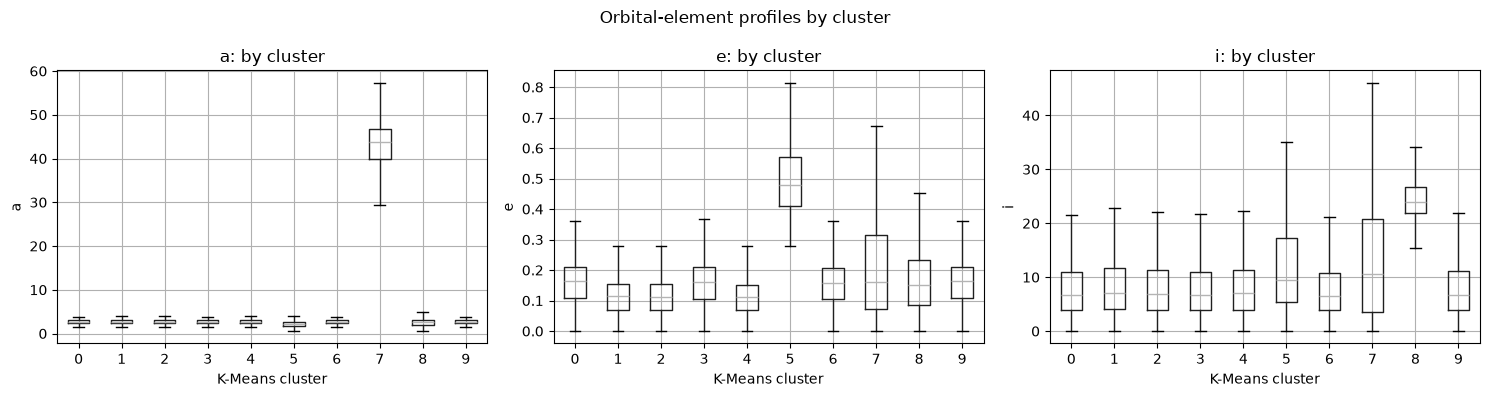

In [26]:
cluster_profile = clustered.groupby("cluster")[orbital_numeric].agg(["count", "mean", "median", "std"])
display(cluster_profile)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, feature in zip(axes, ["a", "e", "i"]):
    clustered.boxplot(column=feature, by="cluster", ax=ax, showfliers=False)
    ax.set_title(f"{feature}: by cluster")
    ax.set_xlabel("K-Means cluster")
    ax.set_ylabel(feature)
plt.suptitle("Orbital-element profiles by cluster")
plt.tight_layout()
plt.show()

## 9. Visualize clusters in a two-dimensional PCA projection

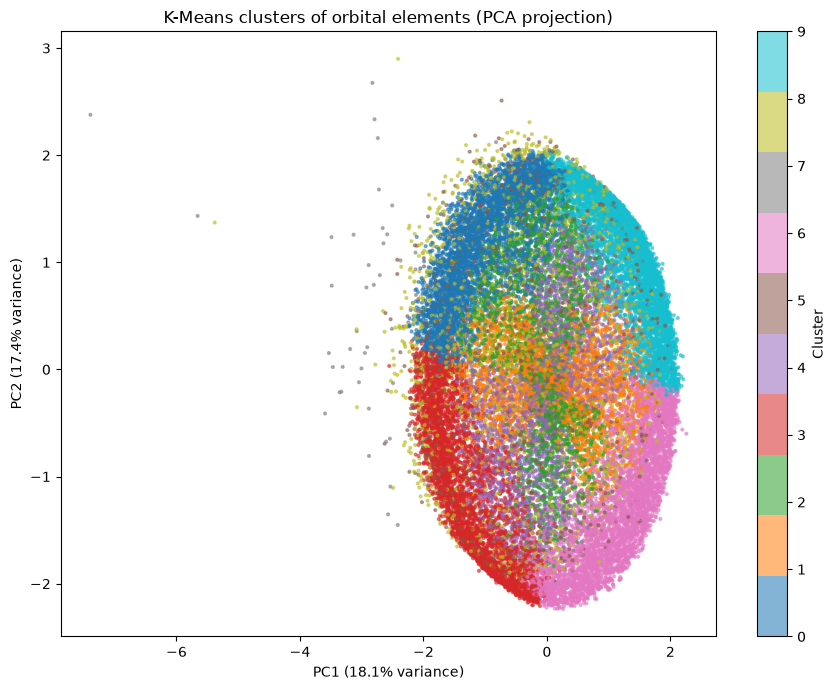

In [27]:
plot_size = min(30_000, len(X_scaled))
plot_indices = np.sort(rng.choice(len(X_scaled), size=plot_size, replace=False))
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled[plot_indices])
plt.figure(figsize=(9, 7))
scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=cluster_labels[plot_indices], cmap="tab10", s=4, alpha=0.55)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.title("K-Means clusters of orbital elements (PCA projection)")
plt.colorbar(scatter, label="Cluster")
plt.tight_layout()
plt.show()

## 10. Compare clusters with existing labels (post hoc only)

These label comparisons are not used to fit K-Means. Cross-tabulations show which existing orbit classes and PHA/NEO flags are enriched in each cluster; they do not mean the cluster is a confirmed asteroid family.

In [28]:
labelled_clusters = clustered.copy()
for label_column in ["class", "pha", "neo"]:
    print(f"\n{label_column}: count by cluster")
    display(pd.crosstab(labelled_clusters["cluster"], labelled_clusters[label_column], normalize="index").round(3))

posthoc_summary = labelled_clusters.groupby("cluster").agg(
    asteroid_count=("a", "size"),
    median_a_AU=("a", "median"),
    median_e=("e", "median"),
    median_i_deg=("i", "median"),
    dominant_orbit_class=("class", lambda values: values.mode().iloc[0] if not values.mode().empty else pd.NA),
    dominant_class_share=("class", lambda values: values.value_counts(normalize=True).iloc[0]),
    neo_share=("neo", lambda values: values.eq("Y").mean()),
    pha_share=("pha", lambda values: values.eq("Y").mean()),
)
display(posthoc_summary.sort_values("asteroid_count", ascending=False).style.format({
    "median_a_AU": "{:.3f}", "median_e": "{:.3f}", "median_i_deg": "{:.2f}",
    "dominant_class_share": "{:.1%}", "neo_share": "{:.2%}", "pha_share": "{:.2%}",
}))


class: count by cluster


class,AMO,APO,AST,ATE,CEN,IEO,IMB,MBA,MCA,OMB,TJN,TNO
cluster,,,,,,,,,,,,
0,0.001,0.002,0.000,0.001,0.000,0.0,0.000,0.951,0.012,0.027,0.006,0.000
1,0.002,0.002,0.000,0.001,0.000,0.0,0.001,0.954,0.002,0.031,0.008,0.000
2,0.003,0.003,0.000,0.001,0.000,0.0,0.007,0.942,0.002,0.032,0.010,0.000
3,0.002,0.003,0.000,0.001,0.000,0.0,0.007,0.939,0.013,0.028,0.008,0.000
4,0.002,0.003,0.000,0.001,0.000,0.0,0.023,0.931,0.003,0.029,0.007,0.000
5,0.240,0.424,0.002,0.035,0.004,0.0,0.000,0.068,0.205,0.022,0.000,0.000
6,0.002,0.002,0.000,0.001,0.000,0.0,0.014,0.933,0.013,0.027,0.008,0.000
7,0.001,0.000,0.000,0.000,0.074,0.0,0.000,0.000,0.000,0.000,0.000,0.925
8,0.020,0.014,0.000,0.003,0.001,0.0,0.218,0.581,0.091,0.048,0.023,0.000



pha: count by cluster


pha,N,Y
cluster,,
0,1.000,0.000
1,1.000,0.000
2,1.000,0.000
3,1.000,0.000
4,1.000,0.000
5,0.925,0.075
6,1.000,0.000
7,1.000,0.000
8,0.997,0.003



neo: count by cluster


neo,N,Y
cluster,,
0,0.996,0.004
1,0.996,0.004
2,0.993,0.007
3,0.994,0.006
4,0.994,0.006
5,0.300,0.700
6,0.995,0.005
7,0.999,0.001
8,0.962,0.038


,asteroid_count,median_a_AU,median_e,median_i_deg,dominant_orbit_class,dominant_class_share,neo_share,pha_share
cluster,,,,,,,,
9,151144,2.654,0.164,6.78,MBA,94.8%,0.43%,0.02%
0,148692,2.652,0.164,6.70,MBA,95.1%,0.39%,0.01%
3,139824,2.664,0.161,6.75,MBA,93.9%,0.56%,0.02%
6,136977,2.647,0.157,6.58,MBA,93.3%,0.47%,0.02%
1,101148,2.664,0.115,7.11,MBA,95.4%,0.40%,0.01%
2,93924,2.664,0.112,6.89,MBA,94.2%,0.67%,0.02%
4,93251,2.642,0.110,7.06,MBA,93.1%,0.64%,0.01%
8,66832,2.594,0.151,23.87,MBA,58.1%,3.78%,0.30%
5,22979,2.254,0.478,9.47,APO,42.4%,69.96%,7.49%


## 11. Interpretation guide

- Clusters separated mainly by semi-major axis may reflect broad orbital zones such as the main belt or near-Earth/high-eccentricity populations.
- Similar eccentricity and inclination profiles with orbital-class enrichment indicate correspondence with an existing dynamical class, not necessarily a collisional family.
- PHA/NEO enrichment is a post-hoc observation only; those flags were not used to form clusters.
- A confirmed asteroid family requires specialist dynamical evidence and usually proper orbital elements. These osculating-element K-Means clusters are exploratory and can be affected by epoch, feature scaling, and the spherical-cluster assumption.